## Setup

In this notebook we will not be performing model training. Instead, you can either run the [Region 2 Results](../tables/region_results.ipynb) notebook first to obtain the best XGB-GMW model or download the trained model [here](https://imperiallondon-my.sharepoint.com/:f:/g/personal/zam25_ic_ac_uk/IgBgU0TXjuEFR63aTh0tIGq1AZOXZ-CILCBPFWHe0s1IRgY?e=YG3nxq) and move the directory to `ROOT_DIR/trained_models`. 

All extent maps will either be required beforehand or be built from the trained model so it's important that you follow either recommendation in order to progress through this notebook. 

In [1]:
import sys

import ee

from mangrove_mapper import MangroveMapper

sys.path.insert(0, "../../../")

PROJECT = "irp-zu"  # Insert your GEE project name

ee.Authenticate()
ee.Initialize(project=PROJECT)

mm = MangroveMapper(project_name=PROJECT)
CONFIG = {key: mm.config[key] for key in ['validation', 'target', 'export', 'default_date_range', 'risk']}
CONFIG

{'validation': {'pomeroon_river_aoi': [[-58.793201027447836,
    7.641999643312983],
   [-58.786311616793554, 7.633424575768573],
   [-58.77487394309828, 7.621191216485879],
   [-58.76182767844984, 7.611492840798936],
   [-58.73607847190687, 7.600433021866128],
   [-58.70311796671348, 7.575930375898359],
   [-58.67016050315687, 7.5568715838076],
   [-58.6444112966139, 7.518070977770642],
   [-58.610422343977184, 7.473139628801602],
   [-58.57076856590101, 7.417820070012739],
   [-58.545191020735, 7.398584252947056],
   [-58.531458993179655, 7.384966344435998],
   [-58.51978657274669, 7.386327054087321],
   [-58.51120232824954, 7.414584961519535],
   [-58.53557798362562, 7.437395480797441],
   [-58.54931089378187, 7.460544404921525],
   [-58.60424253440687, 7.528622363801614],
   [-58.63994810081312, 7.576270580861263],
   [-58.69625303245375, 7.632080358980546],
   [-58.76217100120375, 7.652496753438371],
   [-58.79101011253187, 7.696558803331786],
   [-58.81273167189868, 7.67352708312

In [2]:
from pathlib import Path

REBUILD = False

DATA = Path("../../../data")
TRAINED = Path("../../../trained_models")
DRIVE_FOLDER = "MangroveMapper_ML_Exports"
AOI = ee.Geometry.Polygon(CONFIG["validation"]["pomeroon_river_aoi"])
YEAR = 2021
START, END = f"{YEAR}-01-01", f"{YEAR}-12-31"
PRIOR = 2020
START_PRIOR, END_PRIOR = f"{PRIOR}-01-01", f"{PRIOR}-12-31"
CRS = "EPSG:32621"
SCALE = 10
TILE = 4096
THRESHOLD = 0.50 # the T50 cut both extent maps use
GEO_CONFIG = CONFIG['risk']['geometry']

# Same GSW product and resolution region_results uses, but exported over the region-2 bounds instead of the AOI polygon.
GSW             = DATA / "gsw_occurrence_10m_region_2_bounds.tif"

WORLDPOP        = DATA / "2020-worldpop-r2.tif"
DYNAMIC         = DATA / f"{YEAR}-dynamicworld-r2.tif"
STACK           = DATA / "feature_stack_region_2.tif"
STACK_PRIOR     = DATA / f"feature_stack_region_2_{PRIOR}.tif"
PROB            = DATA / f"{YEAR}-prob-xgb-gmw.tif"
PROB_PRIOR      = DATA / f"{PRIOR}-prob-xgb-gmw.tif"
EXTENT_MAP_2021 = DATA / f"{YEAR}-extent-xgb-gmw-T50.tif"
EXTENT_MAP_2020 = DATA / f"{PRIOR}-extent-xgb-gmw-T50.tif"
MODEL           = TRAINED / "xgb_6k_gmw_full_fusion.json"
TRAINING_CSV    = DATA / "training_data_coastwide.csv"

print(f"REBUILD: {REBUILD}")

REBUILD: False


## 1. Load GeoTiff files & Download missing files

In [3]:
import pandas as pd
import rasterio
from rasterio.warp import transform_bounds

from mangrove_mapper.inference import mosaic
from mangrove_mapper.models import MangroveClassifier

if REBUILD or not TRAINING_CSV.exists():
    mm.get_sensor_data(TRAINING_CSV.stem, CONFIG["target"]["dataset_id"], presence_only=True)
    
_cols = pd.read_csv(TRAINING_CSV, nrows=1).columns
FEATS = [c for c in _cols if c not in MangroveClassifier().NON_FEATURES]

def region_stack(start, end):
    """The 35-band region-2 stack for one year, in the model's feature order."""
    sensors = [Landsat8(start, end, AOI, PROJECT),
               Sentinel2(start, end, AOI, PROJECT),
               Sentinel1(start, end, AOI, PROJECT),
               ALOSPalsar(start, end, AOI, PROJECT)]
    return concat_sensors(sensors).toFloat().select(FEATS).clip(AOI)


if REBUILD or not STACK.exists():
    tiles = mm.export_image_tiled(region_stack(START, END), STACK.stem,
                                  scale=SCALE, crs=CRS, aoi=AOI, tile=TILE,
                                  folder=DRIVE_FOLDER, output_dir=DATA)
    mosaic(sorted(tiles), STACK, nodata=None)

with rasterio.open(STACK) as src:
    T, GRID_CRS = src.transform, src.crs
    H, W = src.height, src.width
    RES = T.a
    INV = ~T
    BOUNDS = transform_bounds(src.crs, "EPSG:4326", *src.bounds)
    FEATS = list(src.descriptions)

# Region-2 bounds, not the AOI polygon: the sea mask needs the ocean seaward of
# the strip, and exposure is sampled landward of it.
REGION_BOX = ee.Geometry.Rectangle(list(BOUNDS), proj="EPSG:4326", geodesic=False)

# One origin for every export, so each layer lands on the stack's grid
GRID = mm.pinned_transform(crs=CRS, scale=SCALE)

print(f"grid {W} x {H} {RES:.0f} m, {GRID_CRS} | {len(FEATS)} features")


def gsw_image():
    return (ee.Image("JRC/GSW1_4/GlobalSurfaceWater").select("occurrence")
            .unmask(0).clip(REGION_BOX).toUint8())


def dynamicworld_image():
    # mode() not mean(): these are class labels (4 = crops, 6 = built)
    return (ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1")
            .filterDate(START, END).filterBounds(REGION_BOX)
            .select("label").mode().clip(REGION_BOX).toUint8())


def worldpop_image():
    # people per 100 m cell; at 10 m this conserves nothing, so it is a
    # relative exposure proxy and never a headcount
    return (ee.ImageCollection("WorldPop/GP/100m/pop")
            .filter(ee.Filter.eq("year", PRIOR))
            .filterBounds(REGION_BOX).mosaic().clip(REGION_BOX).toFloat())


if REBUILD or not GSW.exists():
    tiles = mm.export_image_tiled(gsw_image(), GSW.stem, crs_transform=GRID, crs=CRS,
                                  aoi=REGION_BOX, tile=TILE, folder=DRIVE_FOLDER,
                                  output_dir=DATA)
    mosaic(sorted(tiles), GSW, nodata=0)

if REBUILD or not DYNAMIC.exists():
    tiles = mm.export_image_tiled(dynamicworld_image(), DYNAMIC.stem, crs_transform=GRID,
                                  crs=CRS, aoi=REGION_BOX, tile=TILE,
                                  folder=DRIVE_FOLDER, output_dir=DATA)
    mosaic(sorted(tiles), DYNAMIC, nodata=0)

if REBUILD or not WORLDPOP.exists():
    tiles = mm.export_image_tiled(worldpop_image(), WORLDPOP.stem, crs_transform=GRID,
                                  crs=CRS, aoi=REGION_BOX, tile=TILE,
                                  folder=DRIVE_FOLDER, output_dir=DATA)
    mosaic(sorted(tiles), WORLDPOP, nodata=None)

for label, path in [("GSW", GSW), ("DynamicWorld", DYNAMIC), ("WorldPop", WORLDPOP)]:
    print(f"  {'OK     ' if path.exists() else 'MISSING'}  {label:13s} {path.name}")

grid 3317 x 3458 10 m, EPSG:32621 | 35 features
  OK       GSW           gsw_occurrence_10m_region_2_bounds.tif
  OK       DynamicWorld  2021-dynamicworld-r2.tif
  OK       WorldPop      2020-worldpop-r2.tif


## 2. Extent maps

We need a 2020 and 2021 extent map in order to examine and compare their seaward mangrove edge. They need to be on the exact same grid. Any movement between years will result in erosion (net negative into 2021) or accretion (net positive into 2021)

In [4]:
from mangrove_mapper.inference import extent_tile, predict_tile
from mangrove_mapper.sensors import ALOSPalsar, Landsat8, Sentinel1, Sentinel2
from mangrove_mapper.utils.fusion import concat_sensors

if REBUILD or not STACK_PRIOR.exists():
    tiles = mm.export_image_tiled(region_stack(START_PRIOR, END_PRIOR), STACK_PRIOR.stem,
                                  scale=SCALE, crs=CRS, aoi=AOI, tile=TILE,
                                  folder=DRIVE_FOLDER, output_dir=DATA)
    mosaic(sorted(tiles), STACK_PRIOR, nodata=None)

# One fitted model for both years, loaded, never retrained.
mc = MangroveClassifier()
model = mc.load_model(MODEL)

if REBUILD or not PROB.exists():
    print(f"  {YEAR}: predicting ...", flush=True)
    predict_tile(model, FEATS, STACK, PROB)

if REBUILD or not EXTENT_MAP_2021.exists():
    ha = extent_tile(PROB, STACK, GSW, THRESHOLD, EXTENT_MAP_2021)
    print(f"  built {EXTENT_MAP_2021.name}: {ha:,.0f} ha mangrove")

if REBUILD or not PROB_PRIOR.exists():
    print(f"  {PRIOR}: predicting ...", flush=True)
    predict_tile(model, FEATS, STACK_PRIOR, PROB_PRIOR)

if REBUILD or not EXTENT_MAP_2020.exists():
    ha = extent_tile(PROB_PRIOR, STACK_PRIOR, GSW, THRESHOLD, EXTENT_MAP_2020)
    print(f"  built {EXTENT_MAP_2020.name}: {ha:,.0f} ha mangrove")

# The edge shift is a difference, so the pair has to share a grid exactly.
with rasterio.open(EXTENT_MAP_2020) as a, rasterio.open(EXTENT_MAP_2021) as b:
    if (a.width, a.height, a.transform) != (b.width, b.height, b.transform):
        raise ValueError("the two extent maps are not on the same grid")
    print(f"{PRIOR}: {int((a.read(1) == 1).sum()):,} px | "
          f"{YEAR}: {int((b.read(1) == 1).sum()):,} px mangrove")

2020: 473,303 px | 2021: 466,185 px mangrove


## 3. Put every raster on one grid

The transects are cast in map coordinates and sampled by rounding to row/col, so subsequent every layer has to sit on the same grid before anything is measured from it. The exports above are pinned to that grid already, so this is a straight copy rather than a resample.

grid 3317 x 3458 10 m, EPSG:32621
mangrove 2021 466,185 px | 2020 473,303 px | water 5,221,986 px
landcover: crops/built 223,619 px | water class kept 6,473,497 px
population: negatives after warp 0 (expect 0) | max 142.6 people/ha


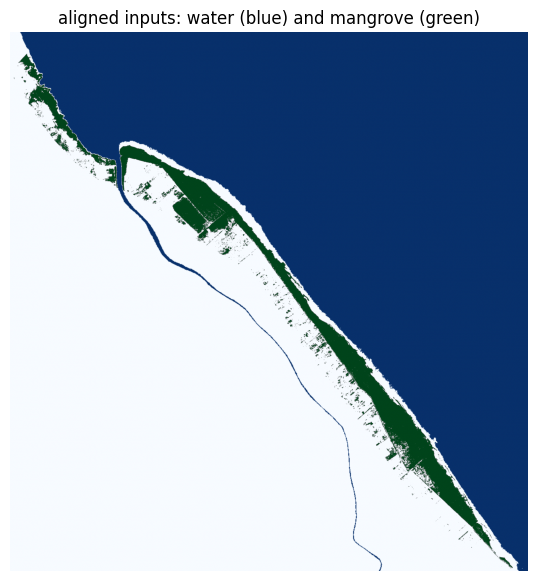

In [5]:
import matplotlib.pyplot as plt
import numpy as np
from rasterio.enums import Resampling

from mangrove_mapper.utils.raster import on_grid

OCC_THRESH = 50   # % GSW occurrence that counts as permanent sea

mangrove = on_grid(EXTENT_MAP_2021, H, W, T, dst_crs=GRID_CRS) == 1          # nodata 255 is declared correctly
mangrove_2020 = on_grid(EXTENT_MAP_2020, H, W, T, dst_crs=GRID_CRS) == 1
water = on_grid(GSW, H, W, T, dst_crs=GRID_CRS, src_nodata=255) >= OCC_THRESH  # 0% occurrence is a real value

# DynamicWorld declares nodata=0, but 0 is the WATER class, not absent data. Overriding with 255.
landcover = on_grid(DYNAMIC, H, W, T, dst_crs=GRID_CRS, src_nodata=255)

# WorldPop declares no nodata at all but uses -200 as its sentinel. Undeclared, the
# bilinear kernel blends -200 into neighbouring real counts; clipping negatives after
# the fact cannot undo that. Declared here, no negative values survive the warp.
population = on_grid(WORLDPOP, H, W, T, dst_crs=GRID_CRS, resampling=Resampling.bilinear, src_nodata=-200)

print(f"grid {W} x {H} {RES:.0f} m, {GRID_CRS}")
print(f"mangrove {YEAR} {mangrove.sum():,} px | {PRIOR} {mangrove_2020.sum():,} px "
      f"| water {water.sum():,} px")
print(f"landcover: crops/built {int(np.isin(landcover, [4, 6]).sum()):,} px "
      f"| water class kept {int((landcover == 0).sum()):,} px")
print(f"population: negatives after warp {int(np.nansum(population < 0))} (expect 0) "
      f"| max {np.nanmax(population):.1f} people/ha")

fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(water, cmap="Blues")
ax.imshow(np.ma.masked_where(~mangrove, mangrove), cmap="Greens_r")
ax.set_title("aligned inputs: water (blue) and mangrove (green)")
ax.axis("off")
plt.show()

## 4. Building Coastline and shore-normal transects

We need to outline the coastline and cast shore-normal transects. We need a smoothed coastline and transects that have both a position (`pts`- transect # & `pos_m` - position along the coastline in m) and direction (`norm`). The sea mask which distinguishes mudflat zone from open water is given as `sea`.

In [6]:
from mangrove_mapper.risk.geometry import build_transects

pts, norm, sea, pos_m = build_transects(water, T, **GEO_CONFIG) 
# also pos_m for transect i = pts[i] * spacing_m 
# where spacing_m is the distance between transects (i.e. 100 m) 

water components: 41   ocean = the largest (5,212,789 px)
coastline 83.0 km -> 830 transect origins at 100 m
flipped 13/830 normals to point landward


### Open-Coast Filtering

Since we're looking at mangroves ability to attentuate incoming waves, we only care about the the open Atlantic front. A transect on an estuary bank faces in the wrong direction landward but an open-coast transect faces kilometres of water. Measuring seaward open water within `rmax_m` number of samples along transect and thresholding them against `>= fetch_min_m` helps to classify transects.

open-coast transects (fetch >= 1500 m): 481/830 (58%)
median fetch: open 3000 m | excluded 160 m


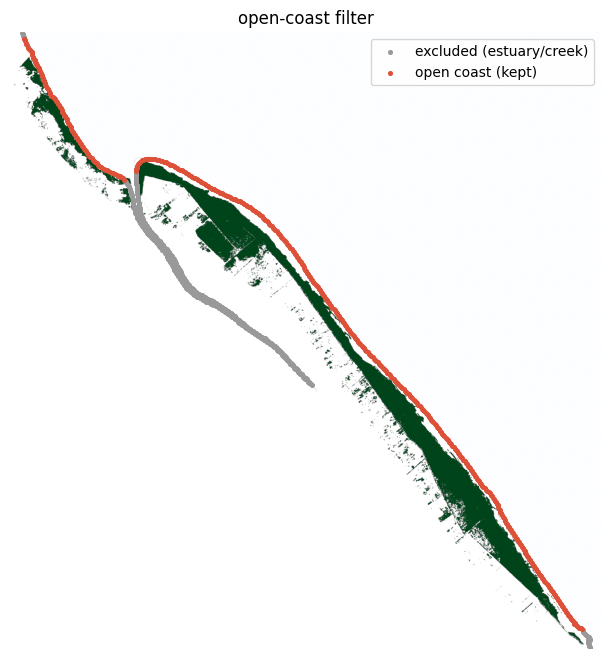

In [7]:
from mangrove_mapper.risk.geometry import seaward_fetch

fetch_m, open_coast = seaward_fetch(pts, norm, sea, INV, **GEO_CONFIG)
q0 = np.array([INV * (x, y) for x, y in pts]) # converts easting/northing, metres to column, row of the array which eventually need to be transposed

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(np.ma.masked_where(~mangrove, mangrove), cmap="Greens_r")
ax.imshow(np.ma.masked_where(~sea, sea), cmap="Blues", alpha=.25)
ax.scatter(*q0[~open_coast].T, s=7, color="#999", label="excluded (estuary/creek)")
ax.scatter(*q0[open_coast].T, s=7, color="#dd5138", label="open coast (kept)")
ax.legend()
ax.set_title("open-coast filter")
ax.axis("off")
plt.show()

## 5. Original Index (Xu et al., 2024)

Constructing pillars of the index such as fringe width, canopy health and fringe structure. Now that the transects are in place, we can use this as a mechnism for sampling. 

In [8]:
from mangrove_mapper.risk.geometry import sample_along
from mangrove_mapper.risk.index import compute_evi, compute_wave_atten, retrieve_hv, robust_stress
from mangrove_mapper.risk.measure import belt_and_mud

config = {**CONFIG['risk']['index'], **GEO_CONFIG} # combining config sections

# Mangrove belt width & region between coastline and mangrove seaward edge, which I'm calling "mudflat"
Wbelt, mudflat = belt_and_mud(mangrove, pts, norm, INV, **config)  
veg = open_coast & (Wbelt > 0)
absent = int((open_coast & (Wbelt == 0)).sum())
print(f"belt median {np.median(Wbelt[veg]):.0f} m | mudflat {np.nanmedian(mudflat[veg]):.0f} m "
      f"| fringe-absent {absent}/{int(open_coast.sum())}")

# attentuation rate per transect based on width of 100 m belt (alongshore)
r = compute_wave_atten(Wbelt, **config)
# EVI & HV values for each pixel in grid
evi = compute_evi(STACK, W, H, GRID_CRS) 
hv_db = retrieve_hv(STACK, W, H, GRID_CRS)

# Scaling health and structure to a risk score between 0 and 1
health_mask = mangrove & np.isfinite(evi)
struct_mask = mangrove & np.isfinite(hv_db)
evi_stress, evi_lim = robust_stress(evi, health_mask)
hv_weakness, hv_lim = robust_stress(hv_db, struct_mask)

print(f"EVI median {np.nanmedian(evi):.3f} | HV median {np.nanmedian(hv_db):.1f} dB")
print(f"EVI 2-98 pct: {evi_lim[0]:.3f} to {evi_lim[1]:.3f}")
print(f"HV  2-98 pct: {hv_lim[0]:.2f} to {hv_lim[1]:.2f} dB")
print(f"canopy pixels {health_mask.sum():,} | structure pixels {struct_mask.sum():,}")

belt median 540 m | mudflat 270 m | fringe-absent 11/481
EVI median 0.280 | HV median -21.3 dB
EVI 2-98 pct: 0.307 to 0.685
HV  2-98 pct: -19.75 to -11.40 dB
canopy pixels 466,185 | structure pixels 466,185


per-transect proxy coverage (open coast):
  EVI :  470/481 finite | median 0.35
  HV  :  470/481 finite | median 0.47


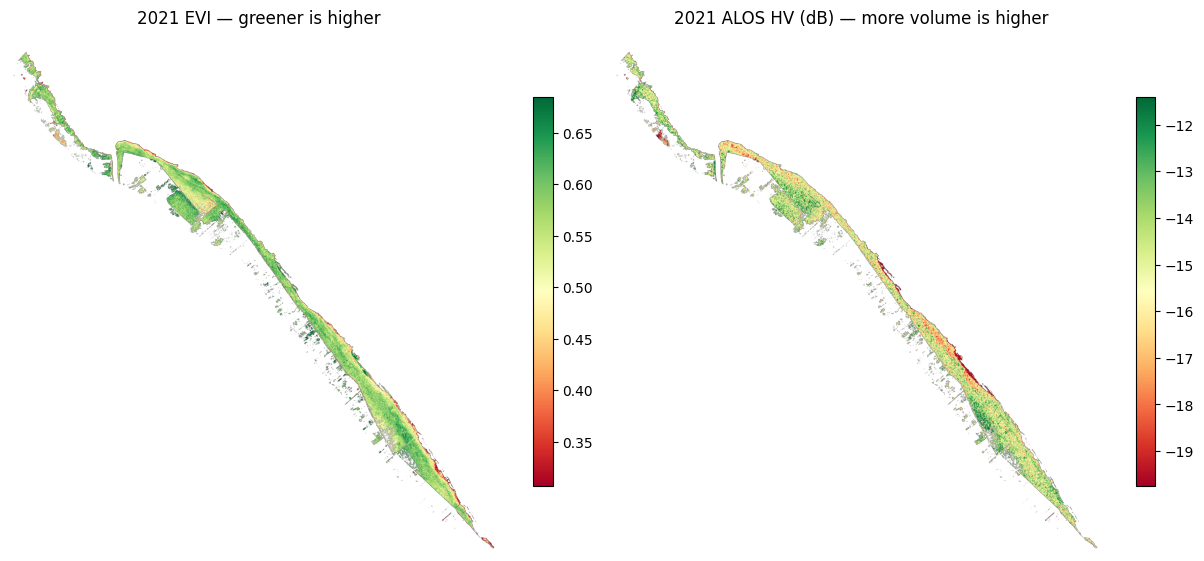

In [9]:
from mangrove_mapper.risk.measure import belt_mean

# Turning variables into per transect measurements
evi_t = np.full(len(pts), np.nan)
hv_t = np.full(len(pts), np.nan)
for i in np.where(open_coast)[0]:
    evi_t[i] = belt_mean(evi_stress, Wbelt, mudflat, pts, norm, INV, i, **config)
    hv_t[i] = belt_mean(hv_weakness, Wbelt, mudflat, pts, norm, INV, i, **config)

print("per-transect proxy coverage (open coast):")
for nm, aa in [("EVI", evi_t), ("HV", hv_t)]:
    v = aa[open_coast]
    print(f"  {nm:4}: {np.isfinite(v).sum():>4}/{int(open_coast.sum())} finite | "
          f"median {np.nanmedian(v):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), constrained_layout=True)
for ax, index, mask, title in [
        (axes[0], evi, health_mask, "2021 EVI — greener is higher"),
        (axes[1], hv_db, struct_mask, "2021 ALOS HV (dB) — more volume is higher")]:
    lo, hi = np.nanpercentile(index[mask], [2, 98])
    im = ax.imshow(np.ma.masked_where(~mask, index), cmap="RdYlGn", vmin=lo, vmax=hi)
    fig.colorbar(im, ax=ax, shrink=.75)
    ax.set_title(title)
    ax.axis("off")
plt.show()

## 7. Adding Erosion

With the inclusion of the effect of erosion, we posit a new risk index, that looks at the seaward edge of mangrove belts between successive years. Transects which map one-to-one between years are examined to see whether they're seaward edge has retreated (erosion) and prograded (accretion) over the year. The edge shift is then min-max scaled and will contribute to a higher risk score if and only if the edge shift is negative. 

In [10]:
from mangrove_mapper.risk.index import compute_erosion_risk
from mangrove_mapper.risk.measure import edge_shift

# Only landward retreat is a hazard; accretion clamps to 0.
edg_shft = edge_shift(mangrove_2020, pts, norm, open_coast, mudflat, INV, **config)
ok_e = open_coast & np.isfinite(edg_shft)
erosion_risk, hi_ret = compute_erosion_risk(edg_shft, open_coast)

print(f"measured on {int(ok_e.sum())}/{int(open_coast.sum())} open-coast transects")
print(f"edge shift m: median {np.nanmedian(edg_shft[ok_e]):+.0f} | "
      f"accreting {(edg_shft[ok_e] > 0).sum()} | eroding {(edg_shft[ok_e] < 0).sum()} | "
      f"stable (<=10 m) {(np.abs(edg_shft[ok_e]) <= 10).sum()}")
print(f"scale: {hi_ret:.0f} m retreat (98th pct) = 1.0 | "
      f"{100 * np.mean(erosion_risk[ok_e] == 0):.0f}% sit at ZERO hazard")

measured on 470/481 open-coast transects
edge shift m: median +0 | accreting 137 | eroding 139 | stable (<=10 m) 272
scale: 100 m retreat (98th pct) = 1.0 | 70% sit at ZERO hazard


## 8. Exposure

Looking at landcover and population we get an estimate of what inland assets are the mangroves protecting. Exposure is an absolute value not relative to other areas in the region. It is aggregated by taking the max score between population and landcover exposed (built-up and crops). 

When sampling within a transect inland for around 4km, population is determined from highest score seen (ppl per ha) and this value saturates at 25 ppl per ha, getting a value of 1.0.
Exposure is determined by the fraction of landward steps that are crops and built up area. For a 4km corridor at 10 m resolution and a step size of 10 m, that's 400 samples + the starting pixel.

In [11]:
from mangrove_mapper.risk.measure import landward_agg

landcover_exp = np.full(len(pts), np.nan)
pop_per_ha = np.full(len(pts), np.nan)
for i in np.where(open_coast)[0]:
    landcover_exp[i] = landward_agg(landcover, i, pts, norm, Wbelt, mudflat, INV, classes=config["exposure_classes"], agg="mean", **config)
    pop_per_ha[i] = landward_agg(population, i, pts, norm, Wbelt, mudflat, INV, **config, agg="max")

pop_exp = np.clip(pop_per_ha / config["pop_full_exposure_per_ha"], 0, 1)

ok_l = open_coast & np.isfinite(landcover_exp)
ok_p = open_coast & np.isfinite(pop_per_ha)
print(f"land use: {(landcover_exp[ok_l] > 0).sum()}/{int(ok_l.sum())} transects have "
      f"crops/built within {config['exposure_depth_m']} m (the rest back onto forest)")
print(f"          fraction crops/built: median {np.nanmedian(landcover_exp[ok_l]):.3f} "
      f"p90 {np.nanpercentile(landcover_exp[ok_l], 90):.3f} "
      f"max {np.nanmax(landcover_exp[ok_l]):.3f}")
print(f"population: people/ha behind the belt ({'max'}): "
      f"median {np.nanmedian(pop_per_ha[ok_p]):.2f} "
      f"p90 {np.nanpercentile(pop_per_ha[ok_p], 90):.2f} "
      f"max {np.nanmax(pop_per_ha[ok_p]):.2f}")
print(f"          against the fixed cap of {config['pop_full_exposure_per_ha']:.0f} people/ha = "
      f"max score {np.nanmax(pop_exp[ok_p]):.2f}")

land use: 244/481 transects have crops/built within 4000 m (the rest back onto forest)
          fraction crops/built: median 0.002 p90 0.479 max 0.994
population: people/ha behind the belt (max): median 0.11 p90 10.25 max 101.34
          against the fixed cap of 25 people/ha = max score 1.00


In [12]:
from mangrove_mapper.risk.measure import landward_steps

# DynamicWorld's own classes ordered
DW_NAMES = ["water", "trees", "grass", "flooded veg.", "crops",
            "shrub & scrub", "built", "bare", "snow & ice"]


# What the landward corridor is made of, over every open-coast transect.
class_counts = np.zeros(len(DW_NAMES))
for i in np.where(open_coast)[0]:
    v = sample_along(landcover, pts[i], norm[i], landward_steps(i, Wbelt, mudflat, **config), INV)
    v = v[np.isfinite(v)]
    if v.size:
        class_counts += np.bincount(np.rint(v).astype(int), minlength=len(DW_NAMES))
share = class_counts / class_counts.sum()

print(f"landward corridor composition ({config['exposure_depth_m']} m behind the belt, "
      f"{int(open_coast.sum())} transects):")
for k in np.argsort(share)[::-1]:
    if share[k] > 0.001:
        flag = "  <= exposure" if k in config['exposure_classes'] else ""
        print(f"  {DW_NAMES[k]:14s} {share[k]:6.1%}{flag}")
print(f"  {'TOTAL exposure':14s} {share[config['exposure_classes']].sum():6.1%}")


landward corridor composition (4000 m behind the belt, 481 transects):
  trees           81.6%
  crops            8.7%  <= exposure
  water            3.9%
  grass            3.6%
  built            0.8%  <= exposure
  shrub & scrub    0.7%
  flooded veg.     0.7%
  TOTAL exposure   9.5%


## 9. Composite Indicator

Here we are agreggating the risk factors based on the PCA results below. 
Geometric and arithmetic mean are used with equal weights and fringe leading weights respectively. These are used to generate the PCA and Monte Carlo sensitivity figures below 

In [13]:
from mangrove_mapper.risk.index import modifier, wgeomean, wmean

# Within-leg weights.
BELT_WEIGHTS = {"fringe": 0.50, "evi": 0.25, "hv": 0.25}
# Between-leg weights
LEG_WEIGHTS = {"belt": 1 / 3, "exposure": 1 / 3, "erosion": 1 / 3}
# Floors for the two legs that are legitimately zero on much of the coast.
EXPOSURE_MIN_MULTIPLIER = 0.25
EROSION_MIN_MULTIPLIER = 0.25

# One axis: width, canopy and structure all load together on PC1.
leg_belt = wmean([r, evi_t, hv_t],
                 [BELT_WEIGHTS["fringe"], BELT_WEIGHTS["evi"], BELT_WEIGHTS["hv"]])
# crops and people are distinct assets, either alone is at stake.
leg_exposure = np.fmax(landcover_exp, pop_exp)
leg_erosion = erosion_risk

exposure_mod = modifier(leg_exposure, EXPOSURE_MIN_MULTIPLIER)
erosion_mod = modifier(leg_erosion, EROSION_MIN_MULTIPLIER)

risk_index = wgeomean([leg_belt, exposure_mod, erosion_mod],
                      [LEG_WEIGHTS["belt"], LEG_WEIGHTS["exposure"],
                       LEG_WEIGHTS["erosion"]])
risk_index[~open_coast] = np.nan

legs = {"belt": leg_belt, "exposure": exposure_mod, "erosion": erosion_mod}
for k, v in legs.items():
    print(f"  {k:10} median {np.nanmedian(v[open_coast]):.3f} | "
          f"min {np.nanmin(v[open_coast]):.3f} | max {np.nanmax(v[open_coast]):.3f} | "
          f"finite {int(np.isfinite(v[open_coast]).sum())}/{int(open_coast.sum())}")
    zeros = int((v[open_coast] == 0).sum())
    if zeros:
        print(f"    WARNING: {k} is exactly 0 on {zeros} transects -> vetoes to 0")

ri = risk_index[open_coast]
print(f"\ncomposite risk index: median {np.nanmedian(ri):.3f} "
      f"p90 {np.nanpercentile(ri, 90):.3f} max {np.nanmax(ri):.3f}")

  belt       median 0.322 | min 0.157 | max 1.000 | finite 481/481
  exposure   median 0.284 | min 0.250 | max 1.000 | finite 481/481
  erosion    median 0.250 | min 0.250 | max 1.000 | finite 470/481

composite risk index: median 0.321 p90 0.500 max 0.900


In [14]:
from scipy.stats import spearmanr

N_DRAWS, W_SEED = 2000, 48
# dirichlet concentration (how tightly drawn weights cluster vs weight defaults)
CONC = 20 # 20 = give or take 0.1 perturbations; std(# of risk legs at equal weights, CONC value)
rng_w = np.random.default_rng(W_SEED) 
oc = np.where(open_coast)[0] # indices of open coast transects (open-coast 511 transects)

leg_names = list(legs) # each risk factor V2 includes belt condition, erosion, exposure
L = np.vstack([legs[k] for k in leg_names]).T[oc] # builds shape (open-coast transects, risk legs) for analysis
fin_L = np.isfinite(L)
lnL = np.where(fin_L, np.log(np.where(fin_L, L, 1.0)), 0.0) # taking the ln of valid weightings, zero-ing out invalid values (NaNs) 

base = np.array([LEG_WEIGHTS[k] for k in leg_names]) # retrieving default weighting (1/3 across all)

# Dirichlet chosen since weights must be non-negative and sum to so every draw is a legit alt weighting
draws = rng_w.dirichlet(CONC * base, size=N_DRAWS) # shape (N draws, 3 weighting legs)
idx_mc = np.empty((N_DRAWS, len(oc))) # results array shape (N, 511)
for d in range(N_DRAWS): 
    wg = fin_L * draws[d] # finite perturbed weights
    idx_mc[d] = np.exp((lnL * wg).sum(1) / wg.sum(1)) # weighted geometric sum (converts out of log space)

idx_def = risk_index[oc] # risk scores with default weights
# N draws / 20 samples, did draws rank the coast in the same order as my defaults?
rhos = np.array([spearmanr(idx_mc[d], idx_def).correlation for d in range(0, N_DRAWS, 20)])
q75 = np.nanpercentile(idx_mc, 75, axis=1, keepdims=True) # 75th percentile risk score per draw across all transects
prob_top_quartile = (idx_mc >= q75).mean(axis=0) # the fraction of weightings from draws that put the transect in the 75th percentile of risk scores
idx_lo, idx_hi = np.percentile(idx_mc, [5, 95], axis=0) # getting the 5th and 95th percentile per transect across draws

print(f"leg weights Dirichlet(conc={CONC}) centred on \n"
      f"{dict(zip(leg_names, base.round(2)))}")
print(f"\nweight std per leg: {dict(zip(leg_names, draws.std(0).round(3)))}")
print(f"\nrank stability vs default: Spearman median {np.median(rhos):.3f} "
      f"(p05 {np.percentile(rhos, 5):.3f})")
print(f"\ntop-quartile (>=90% of draws): "
      f"{int((prob_top_quartile >= 0.9).sum())}/{len(oc)} transects")
print(f"\nmedian 90% index interval width: {np.median(idx_hi - idx_lo):.3f}")

leg weights Dirichlet(conc=20) centred on 
{'belt': np.float64(0.33), 'exposure': np.float64(0.33), 'erosion': np.float64(0.33)}

weight std per leg: {'belt': np.float64(0.103), 'exposure': np.float64(0.105), 'erosion': np.float64(0.106)}

rank stability vs default: Spearman median 0.971 (p05 0.874)

top-quartile (>=90% of draws): 67/481 transects

median 90% index interval width: 0.069


## Figure 1 
### PCA A-B Risk Comparison and Monte Carlo Sensitivity Test

Risk Index V1 (Spearman) variance explained: PC1=56%  PC2=26%  PC3=18%
Risk Index V2 (Spearman) variance explained: PC1=31%  PC2=25%  PC3=18%  PC4=12%  PC5=9%  PC6=6%

Rank stability vs Default: Spearman median 0.971 (p05 0.874)

wrote risk_index_figure1.png


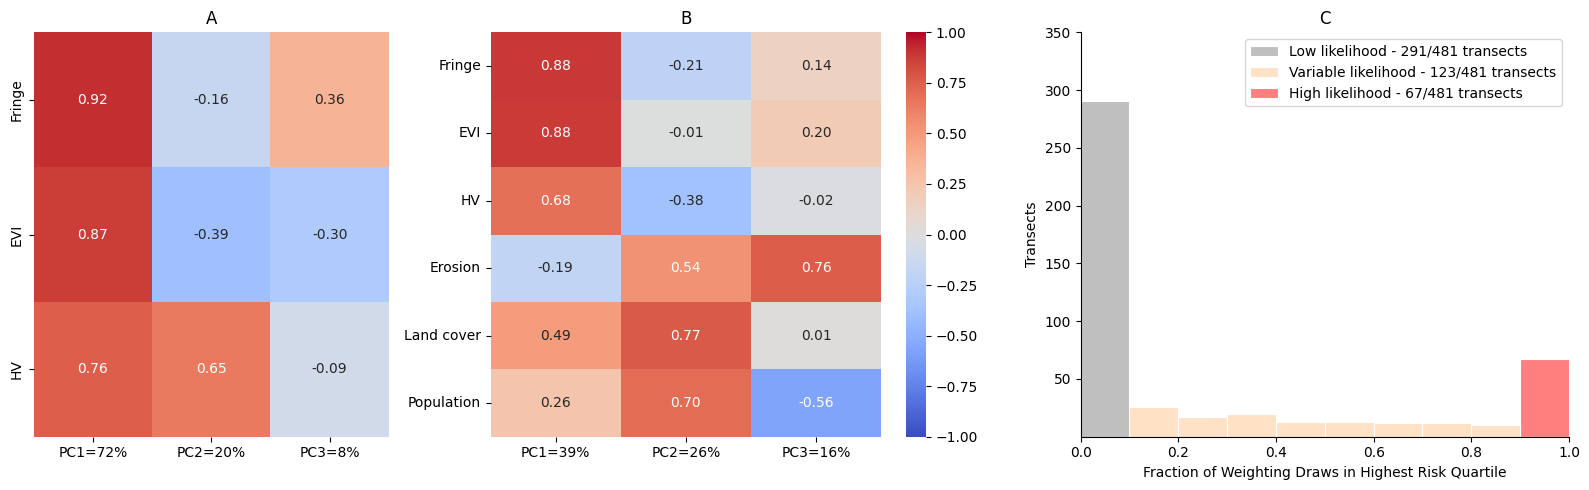

In [21]:
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

titles = ['A', 'B', 'C']
fig, axes = plt.subplots(1, 3, figsize=(16, 5), gridspec_kw={"width_ratios": [0.8, 1.1, 1.1]})

# PCA plots
FACTOR_LABELS = {"fringe": "Fringe", "evi": "EVI",
                 "hv": "HV", "erosion": "Erosion",
                 "landcover": "Land cover", "population": "Population"}

# V1: Original Xu et al., (2024) esque 
# V2: Additional factors Erosion, Exposure (Landcover, Population)
F_V1 = pd.DataFrame({"fringe": r, "evi": evi_t, "hv": hv_t})[open_coast].dropna()
F_V2 = pd.DataFrame({"fringe": r, "evi": evi_t, "hv": hv_t, "erosion": erosion_risk,
                     "landcover": landcover_exp, "population": pop_exp})[open_coast].dropna()

cmap = "coolwarm"

for idx, f in enumerate([F_V1, F_V2]):
    scaled_f = StandardScaler().fit_transform(f)
    pca_pearson = PCA()
    pca_pearson.fit(scaled_f)
    var_pearson = pd.Series(pca_pearson.explained_variance_ratio_,
                    index=[f"PC{i+1}" for i in range(pca_pearson.n_components_)])
    cols = [f"{k}={v:.0%}" for k,v in var_pearson.items()]
    loadings = pd.DataFrame(pca_pearson.components_.T * np.sqrt(pca_pearson.explained_variance_), index=f.columns,
                        columns=cols)
    
    scaled_rank = StandardScaler().fit_transform(f.rank())
    pca_spearman = PCA()
    pca_spearman.fit(scaled_rank)
    var_spearman = pd.Series(pca_spearman.explained_variance_ratio_,
                    index=[f"PC{i+1}" for i in range(pca_spearman.n_components_)])
    sns.heatmap(loadings.iloc[:, :3], vmin=-1, vmax=1, cmap=cmap, ax=axes[idx],
            yticklabels=[FACTOR_LABELS[k] for k in loadings.index], cbar=(idx==1),
            xticklabels=cols[:3], annot=True, fmt=".2f")
    axes[idx].set_title(titles[idx])
    axes[idx].set_anchor("N")

    print(f"Risk Index V{idx + 1} (Spearman) variance explained:", "  ".join(f"{k}={v:.0%}" for k, v in var_spearman.items()))

# MC plot
LOW, HIGH = 0.1, 0.9
group = np.where(prob_top_quartile < LOW, "low", np.where(prob_top_quartile >= HIGH, "high", "middle"))
n = {g: int((group == g).sum()) for g in ("low", "middle", "high")}
total = len(prob_top_quartile)
legend_keys = {"low": "Low likelihood", "middle": "Variable likelihood", "high": "High likelihood"}
labels = {g: f"{legend_keys[g]} - {n[g]}/{total} transects" for g in n}
df = pd.DataFrame({"score": prob_top_quartile, "groups": [labels[g] for g in group]})

order = [labels["low"], labels["middle"], labels["high"]]
palette = dict(zip(order, ["gray", "#ffc58e", "red"]))

mcp = axes[2]
mcp.set_title(titles[2])
sns.histplot(df, x="score", bins=10, ax=mcp, hue="groups", binrange=(0, 1), hue_order=order,
             palette=palette, edgecolor="white", linewidth=0.8)
mcp.set_xlim(0, 1)
mcp.set_yticks([t for t in mcp.get_yticks() if t != 0])
mcp.set_xlabel("Fraction of Weighting Draws in Highest Risk Quartile")
mcp.set_ylabel("Transects")
for side in ("top", "right"):
    mcp.spines[side].set_visible(False)
sns.move_legend(mcp, "upper right", title=None, frameon=True)

    
print(f"\nRank stability vs Default: Spearman median {np.median(rhos):.3f} "
      f"(p05 {np.percentile(rhos, 5):.3f})")

plt.tight_layout()
out = "risk_index_figure1.png"
fig.savefig(out, dpi=300, bbox_inches="tight")
print(f"\nwrote {out}")

## Figure 2
### Region 2 Extent Map with V2 Risk Index Overlaid

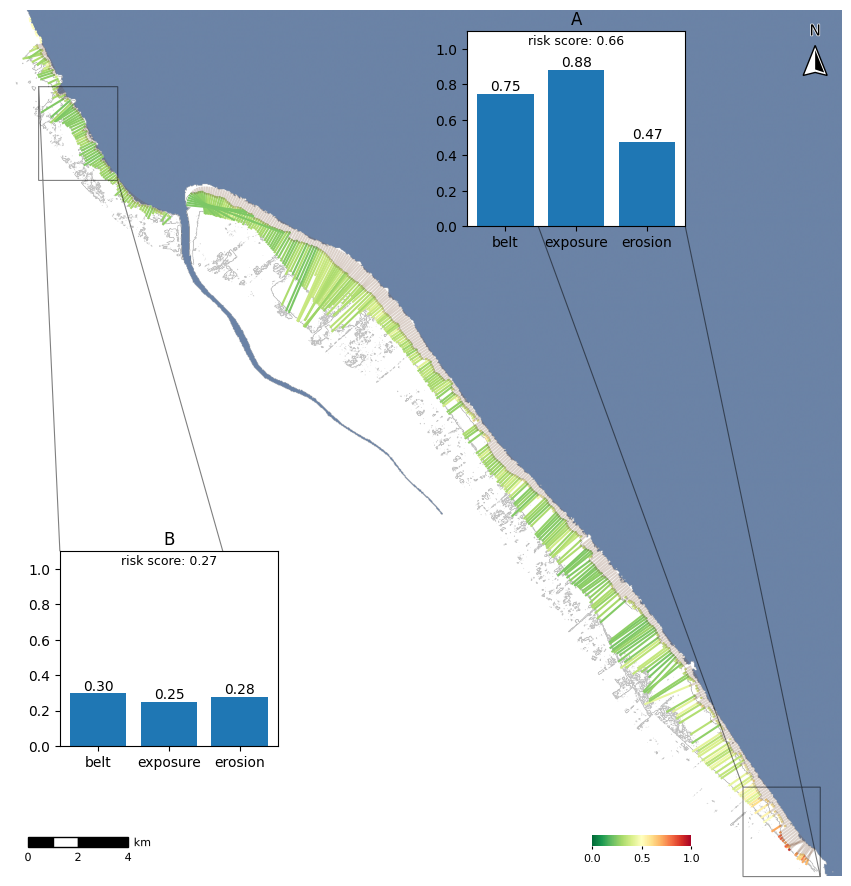


wrote risk_index_figure2.png


In [30]:
from matplotlib_map_utils import north_arrow, scale_bar
from rasterio.plot import plotting_extent

m0 = np.where(np.isfinite(mudflat), mudflat, 0.0)
L  = np.maximum(Wbelt, config['step_m']) # drawn length of belt
A  = pts + m0[:, None] * norm          # seaward edge of the belt
B  = pts + (m0 + L)[:, None] * norm    # landward edge of the belt



fig, ax = plt.subplots(figsize=(9, 9))
ext = plotting_extent(mangrove, transform=T)
cmap, nrm = plt.cm.RdYlGn_r, plt.Normalize(0, 1)

ax.imshow(np.ma.masked_where(~mangrove, mangrove), cmap="Greys", extent=ext)
ax.imshow(np.ma.masked_where(~sea, sea), cmap="Blues", extent=ext, alpha=.6, vmin=0, vmax=1)
ax.axis('off')
for i in np.where(open_coast)[0]:
    if not np.isfinite(risk_index[i]): continue
    p = pts[i]
    m0 = mudflat[i] if not np.isnan(mudflat[i]) else 0.0
    a = p + m0 * norm[i]
    b = p + (m0 + max(Wbelt[i], config['step_m'])) * norm[i]
    # risk indexed transects
    ax.plot([a[0], b[0]], [a[1], b[1]], color=cmap(nrm(risk_index[i])))
    # area between sea and first mangroves aka "mudflat" (not actually)
    c = pts[i] + mudflat[i] * norm[i]
    ax.plot([pts[i][0], c[0]], [pts[i][1], c[1]], color="#74492e", alpha=.25)

sm=plt.cm.ScalarMappable(norm=nrm,cmap=cmap)
cax = ax.inset_axes([0.70, 0.035, 0.12, 0.012])
cb = fig.colorbar(sm, cax=cax, shrink=.4, orientation="horizontal")
cb.outline.set_visible(False)
cb.ax.tick_params(labelsize=8, length=2)
cb.ax.ticklabel_format()

north_arrow(
    ax, location="upper right", scale=0.3,
    fancy=True, shadow=False, label={"position": "top", "text": "N",
                                     "fontfamily": "sans-serif", "fontsize": 11})
scale_bar(ax, location="lower left", style="boxes",
              bar={"projection": GRID_CRS.to_string(), "unit": "km",
                   "max": 4, "major_div": 2, "minor_div": 2},
              labels={"fontsize": 8, "fontfamily": "sans-serif", "sep": 1, "loc": "below"},
              units={"fontsize": 8, "fontfamily": "sans-serif"})

win = 30 # num transects as window 
# rolling mean of risk index over consecutive transects
rolling_mean = pd.Series(risk_index).rolling(win, center=True, min_periods=win).mean()
idx_min, idx_max  = rolling_mean.idxmin(), rolling_mean.idxmax()
# (MAX) transect start and end with highest risk score
hi_0, hi_1 = idx_max - win//2, idx_max + win//2 + 1
# (MIN) transect start and end with lowest risk score
lo_0, lo_1 = idx_min - win//2, idx_min + win//2 + 1

score_hi = ax.inset_axes([0.55, 0.75, 0.2625, 0.225])
score_lo = ax.inset_axes([0.06, 0.15, 0.2625, 0.225])
panels = [
    (score_hi, 'A', (hi_0, hi_1), rolling_mean.max()), 
    (score_lo, 'B', (lo_0, lo_1), rolling_mean.min())
    ]

pad = 500
for (axc, title, score, composite)  in panels:
    v = np.vstack([A[score[0]:score[1]], B[score[0]:score[1]]]) # every A to B point in inset box 
    bounds = [v[:,0].min()-pad, v[:,1].min()-pad,
            np.ptp(v[:,0])+2*pad, np.ptp(v[:,1])+2*pad]
    ax.indicate_inset(bounds, inset_ax=axc, edgecolor="black", lw=0.8, label="A")

    ri_bars = axc.bar(range(3),
        [
            np.nanmean(leg_belt[score[0]:score[1]]), 
            np.nanmean(exposure_mod[score[0]:score[1]]), 
            np.nanmean(erosion_mod[score[0]:score[1]])
        ]
    )
    axc.set_xticks(range(3), ["belt", "exposure", "erosion"])
    axc.bar_label(ri_bars, padding=0, fmt="%.2f")
    axc.set_ylim(0, 1.1)
    axc.set_title(title, pad=5)
    axc.text(0.5, 0.93, f"risk score: {composite:.2f}", transform=axc.transAxes, fontsize=9, ha="center")
    
plt.tight_layout()
plt.show()
out = "risk_index_figure2.png"
fig.savefig(out, dpi=300, bbox_inches="tight")
print(f"\nwrote {out}")